# Does money buy happiness?
Scientific Data Visualization project made by Fabio Anchisi, Gabriela Simon and Riccardo Gaglio.

Code behind the slides. Run it from top to bottom, the tables for the charts are saved in `outputs/`.

Data: World Happiness Report (WHR26_Data_Figure_2.1.xlsx, report years 2019 to 2024) and World Bank indicators (the API_*.csv files).
Income is GDP per capita, PPP (constant 2021 international $).

The plots from slides 5, 6, 7, 12, 13, 15 were re-plotted on Flourish with the datasets created in this notebook. The plots from slide 8 were re-plotted on Datawrapper.

Some plots were not used in the final presentation.

The final presentation can be found on the link: https://canva.link/tcii2mv33xsc8gt

## Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
import country_converter as conv
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

DATA = Path(".")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

TEAL, ORANGE = "#2A7F86", "#E8902F"

## Cleaning the WHR data
Keep 2019 to 2024, add ISO3 codes, drop North Cyprus (same code as Cyprus), rename columns, add continent and region.

In [2]:
df = pd.read_excel(DATA / "WHR26_Data_Figure_2.1.xlsx")
df = df[(df["Year"] >= 2019) & (df["Year"] <= 2024)].copy()
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])

(875, 13)
Explained by: Log GDP per capita              3
Explained by: Social support                  3
Explained by: Healthy life expectancy         5
Explained by: Freedom to make life choices    4
Explained by: Generosity                      3
Explained by: Perceptions of corruption       4
Dystopia + residual                           7
dtype: int64


In [3]:
names = df["Country name"].unique()
mapping = dict(zip(names, conv.convert(names=names, to="ISO3")))
print([n for n, c in mapping.items() if c == "not found"])
df["iso3"] = df["Country name"].map(mapping)

df = df[df["Country name"] != "North Cyprus"].copy()
print(df.duplicated(["iso3", "Year"]).sum())   # should be 0

df["Country name"] = df["Country name"].replace({"Swaziland": "Eswatini"})

[]
0


In [4]:
df = df.rename(columns={
    "Life evaluation (3-year average)": "score",
    "Lower whisker": "lo", "Upper whisker": "hi",
    "Explained by: Log GDP per capita": "gdp",
    "Explained by: Social support": "social",
    "Explained by: Healthy life expectancy": "health",
    "Explained by: Freedom to make life choices": "freedom",
    "Explained by: Generosity": "generosity",
    "Explained by: Perceptions of corruption": "corruption",
    "Dystopia + residual": "residual",
    "Country name": "country", "Year": "year", "Rank": "rank"})

print(df.groupby("iso3")["year"].nunique().value_counts().sort_index())

year
1      5
2      4
3      3
4      1
5      6
6    136
Name: count, dtype: int64


In [5]:
iso_unique = df["iso3"].unique()
df["continent"] = df["iso3"].map(dict(zip(iso_unique, conv.convert(names=iso_unique, src="ISO3", to="continent"))))
df["subregion"] = df["iso3"].map(dict(zip(iso_unique, conv.convert(names=iso_unique, src="ISO3", to="UNregion"))))

region_map = {
    "Northern Europe": "Northern & Western Europe",
    "Western Europe": "Northern & Western Europe",
    "Southern Europe": "Southern Europe",
    "Eastern Europe": "Eastern Europe",
    "Northern America": "North America",
    "Australia and New Zealand": "Oceania",
    "South America": "South America",
    "Central America": "Central America & Caribbean",
    "Caribbean": "Central America & Caribbean",
    "Western Asia": "Middle East & North Africa",
    "Northern Africa": "Middle East & North Africa",
    "Eastern Africa": "Sub-Saharan Africa",
    "Western Africa": "Sub-Saharan Africa",
    "Middle Africa": "Sub-Saharan Africa",
    "Southern Africa": "Sub-Saharan Africa",
    "Eastern Asia": "East Asia",
    "South-eastern Asia": "Southeast Asia",
    "Southern Asia": "South Asia",
    "Central Asia": "Central Asia",
}
df["region"] = df["subregion"].map(region_map)
print(df["region"].isna().sum())

df = df.sort_values(["iso3", "year"]).reset_index(drop=True)
df.to_csv(OUT / "whr_2019_2024_clean.csv", index=False)

0


## Merging the World Bank indicators
Each file is wide (one column per year), so it is melted to long and joined on iso3 and year.
`gdp_ppp` is the income used in the analysis, `gdp_pc` (current US$) is only kept for reference.

In [6]:
files = {
    "API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv": "gdp_pc",
    "API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_1629.csv": "gdp_ppp",
    "API_SP.POP.TOTL_DS2_en_csv_v2_5254.csv": "population",

}

merged = df.copy()
for fname, col in files.items():
    raw = pd.read_csv(DATA / fname, skiprows=4)
    long = raw.melt(id_vars=["Country Code"],
                    value_vars=[c for c in raw.columns if c.isdigit()],
                    var_name="year", value_name=col)
    long["year"] = long["year"].astype(int)
    long = long.rename(columns={"Country Code": "iso3"})
    merged = merged.merge(long, on=["iso3", "year"], how="left")

print(merged.shape, len(df))      # same number of rows
print(merged[list(files.values())].isna().sum())
print(sorted(merged.loc[(merged["year"] == 2024) & merged["gdp_ppp"].isna(), "country"]))   # no PPP data
merged.to_csv(OUT / "merged_datasets_2019_to_2024.csv", index=False)

(872, 20) 872
gdp_pc        12
gdp_ppp       18
population     6
dtype: int64
['Taiwan Province of China', 'Venezuela', 'Yemen']


In [7]:
for region_name, r_group in df.groupby('region'):
    print(f"\nREGION: {region_name}")
    for subregion_name, sr_group in r_group.groupby('subregion'):
        countries = sorted(sr_group['country'].dropna().unique())
        print(f"Subregion: {subregion_name} ({len(countries)} countries)")
        print(f"{', '.join(countries)}")


REGION: Central America & Caribbean
Subregion: Caribbean (4 countries)
Dominican Republic, Haiti, Jamaica, Trinidad and Tobago
Subregion: Central America (8 countries)
Belize, Costa Rica, El Salvador, Guatemala, Honduras, Mexico, Nicaragua, Panama

REGION: Central Asia
Subregion: Central Asia (5 countries)
Kazakhstan, Kyrgyzstan, Tajikistan, Turkmenistan, Uzbekistan

REGION: East Asia
Subregion: Eastern Asia (6 countries)
China, Hong Kong SAR of China, Japan, Mongolia, Republic of Korea, Taiwan Province of China

REGION: Eastern Europe
Subregion: Eastern Europe (10 countries)
Belarus, Bulgaria, Czechia, Hungary, Poland, Republic of Moldova, Romania, Russian Federation, Slovakia, Ukraine

REGION: Middle East & North Africa
Subregion: Northern Africa (5 countries)
Algeria, Egypt, Libya, Morocco, Tunisia
Subregion: Western Asia (16 countries)
Armenia, Azerbaijan, Bahrain, Cyprus, Georgia, Iraq, Israel, Jordan, Kuwait, Lebanon, Oman, Saudi Arabia, State of Palestine, Türkiye, United Arab 

## Picture for slide 4
Saved in HTML

In [8]:
# Renaming countries to match dataset names
name_mapping = {
    'United States': 'United States of America',
    'Democratic Republic of the Congo': 'Dem. Rep. Congo',
    'Congo': 'Congo',
    'Türkiye': 'Turkey',
    'Czechia': 'Czech Republic',
    'South Korea': 'Korea, South',
    'Taiwan Province of China': 'Taiwan',
    'Hong Kong SAR of China': 'Hong Kong',
    'State of Palestine': 'Palestine'
}
merged['mapped_country'] = merged['country'].replace(name_mapping)

fig = px.choropleth(
    merged.drop_duplicates(subset=['country']),
    locations="mapped_country",  
    locationmode="country names",
    color="continent",  
    hover_name="country",
    hover_data=["score", "gdp_pc"],
    title="Mappa Globale: Copertura dei Paesi e dei Continenti nel Dataset (2019-2024)",
    template="plotly_white"
)

fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='natural earth'
    ),
    legend_title_text='Continenti'
)

# Interactive html map saved to file
fig.write_html(OUT /"happiness_in_continents.html")

## Map and box plots 
Made in Flourish, so here is only the data they use.

In [9]:
cols = ["country", "iso3", "year", "score", "lo", "hi", "continent", "region"]
merged[cols].to_csv(OUT / "flourish_map_and_boxplots.csv", index=False)
merged.loc[merged["year"] == 2024, cols].to_csv(OUT / "flourish_boxplots_2024.csv", index=False)
merged.groupby("year")["score"].agg(["count", "min", "max", "mean"]).round(2)

,count,min,max,mean
year,,,,
2019,152,2.57,7.81,5.47
2020,148,2.52,7.84,5.53
2021,145,2.40,7.82,5.55
2022,137,1.86,7.80,5.54
2023,143,1.72,7.74,5.53
2024,147,1.36,7.74,5.58


In [10]:
mena_top_20 = (
    df[
        (df['region'].str.contains('Middle East', case=False, na=False))
        & (df['year'] == 2024)]
    .sort_values(by='score', ascending=False)
    .head(20)[['year', 'country', 'score']]
    .reset_index(drop=True))
print(mena_top_20)

    year               country  score
0   2024                Israel  7.234
1   2024  United Arab Emirates  6.759
2   2024                Kuwait  6.629
3   2024          Saudi Arabia  6.600
4   2024                  Oman  6.197
5   2024               Bahrain  6.030
6   2024                Cyprus  5.942
7   2024                 Libya  5.820
8   2024               Algeria  5.571
9   2024               Armenia  5.494
10  2024               Georgia  5.400
11  2024               Türkiye  5.262
12  2024                  Iraq  4.976
13  2024            Azerbaijan  4.875
14  2024    State of Palestine  4.780
15  2024               Morocco  4.622
16  2024               Tunisia  4.552
17  2024                Jordan  4.310
18  2024                 Egypt  3.817
19  2024                 Yemen  3.561


## Population by happiness category 
Made in Datawrapper. Countries are put in a category by their 2024 score and their population is added up,
overall (as a share) and by region (in millions).

In [11]:
pop = merged[merged["year"] == 2024].dropna(subset=["score", "population"]).copy()
labels = ["Very bad (<4)", "Bad (4-5)", "Moderate (5-6)", "Good (6-7)", "Very good (≥7)"]
pop["category"] = pd.cut(pop["score"], bins=[0, 4, 5, 6, 7, 10], labels=labels, right=False)

share = pop.groupby("category", observed=False)["population"].sum()
share = (share / share.sum() * 100).round(1)
share.to_csv(OUT / "datawrapper_population_share.csv")

by_region = (pop.pivot_table(index="region", columns="category", values="population",
                             aggfunc="sum", observed=False) / 1e6).round(1)
by_region.to_csv(OUT / "datawrapper_population_by_region.csv")
print(share)
by_region

category
Very bad (<4)     10.0
Bad (4-5)         32.6
Moderate (5-6)    31.5
Good (6-7)        25.1
Very good (≥7)     0.8
Name: population, dtype: float64


category,Very bad (<4),Bad (4-5),Moderate (5-6),Good (6-7),Very good (≥7)
region,,,,,
Central America & Caribbean,0.0,0.0,26.5,167.5,5.1
Central Asia,0.0,0.0,17.8,57.0,0.0
East Asia,0.0,0.0,1420.0,175.7,0.0
Eastern Europe,0.0,37.9,162.1,71.9,0.0
Middle East & North Africa,162.9,123.4,147.9,58.1,10.0
North America,0.0,0.0,0.0,381.3,0.0
Northern & Western Europe,0.0,0.0,0.0,262.9,46.8
Oceania,0.0,0.0,0.0,32.5,0.0
South America,0.0,0.0,93.2,340.7,0.0


Base versions of the two charts (the final ones were made in Datawrapper).

In [12]:
# Take 2024 to avoid multiplying population across multiple years
df_2024 = merged[merged['year'] == 2024].copy()

def categorize_score_5(s):
  if s < 4:
    return 'Very bad (<4)'
  elif s < 5:
    return 'Bad (4-5)'
  elif s < 6:
    return 'Moderate (5-6)'
  elif s < 7:
    return 'Good (6-7)'
  else:
    return 'Very good (>=7)'

df_2024['happiness_tier'] = df_2024['score'].apply(categorize_score_5)
tier_order = [
    'Very bad (<4)',
    'Bad (4-5)',
    'Moderate (5-6)',
    'Good (6-7)',
    'Very good (>=7)',
]

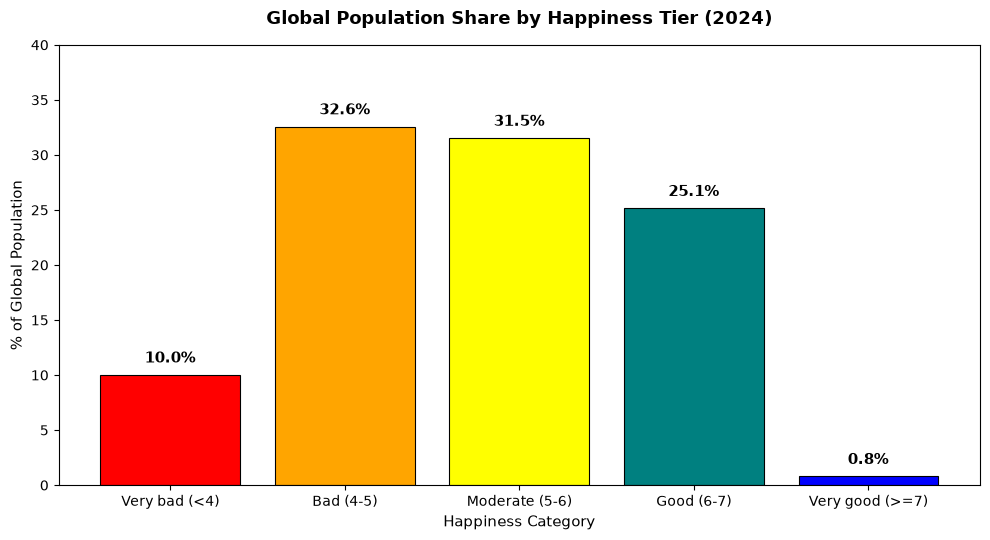

In [13]:
# Calculate population sum and percentage share per tier
pop_tier = (
    df_2024.groupby('happiness_tier')['population']
    .sum()
    .reindex(tier_order, fill_value=0)
)
pop_pct = (pop_tier / pop_tier.sum()) * 100

plt.figure(figsize=(10, 5.5))
colors = ['red', 'orange', 'yellow', 'teal', 'blue']
bars = plt.bar(
    tier_order, pop_pct, color=colors, edgecolor='black', linewidth=0.8
)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.8,
      f'{yval:.1f}%',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=11,
  )

plt.title(
    'Global Population Share by Happiness Tier (2024)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.ylabel('% of Global Population', fontsize=11)
plt.xlabel('Happiness Category', fontsize=11)
plt.ylim(0, 40)
plt.tight_layout()
plt.show()

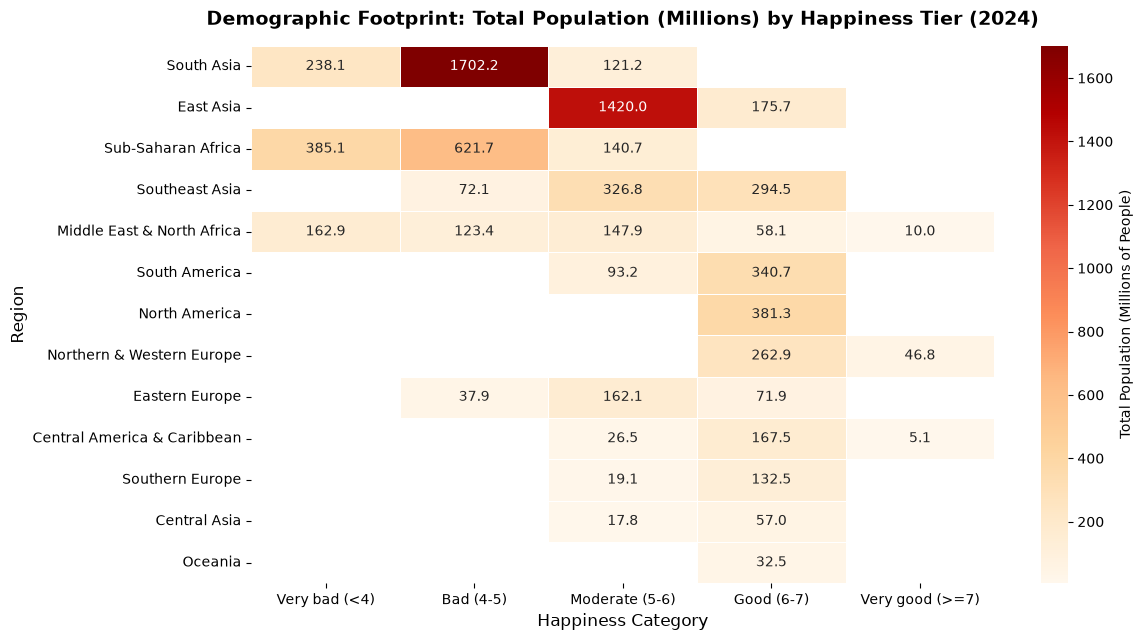

In [14]:
# Sum population in millions
pivot_pop = df_2024.groupby(['region', 'happiness_tier'])['population'].sum().unstack().reindex(columns=tier_order, fill_value=0) / 1e6

# Sort regions by total population
pivot_pop = pivot_pop.loc[pivot_pop.sum(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(12, 6.5))
sns.heatmap(
    pivot_pop,
    annot=True,
    fmt='.1f',
    cmap='OrRd',
    cbar_kws={'label': 'Total Population (Millions of People)'},
    linewidths=0.5
)
plt.title('Demographic Footprint: Total Population (Millions) by Happiness Tier (2024)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Region', fontsize=12)
plt.xlabel('Happiness Category', fontsize=12)
plt.tight_layout()
plt.show()

## Income and happiness over time
Slides 9, 10 and 11. Median score and median income by year, then the change from 2019 to 2024 and the four quadrants (richer or poorer, happier or less happy).

Income in these three slides is `gdp_pc` (GDP per capita in current US$), not the PPP income used in the other slides.

### Slide 9: happiness score vs GDP per capita, global and by continent

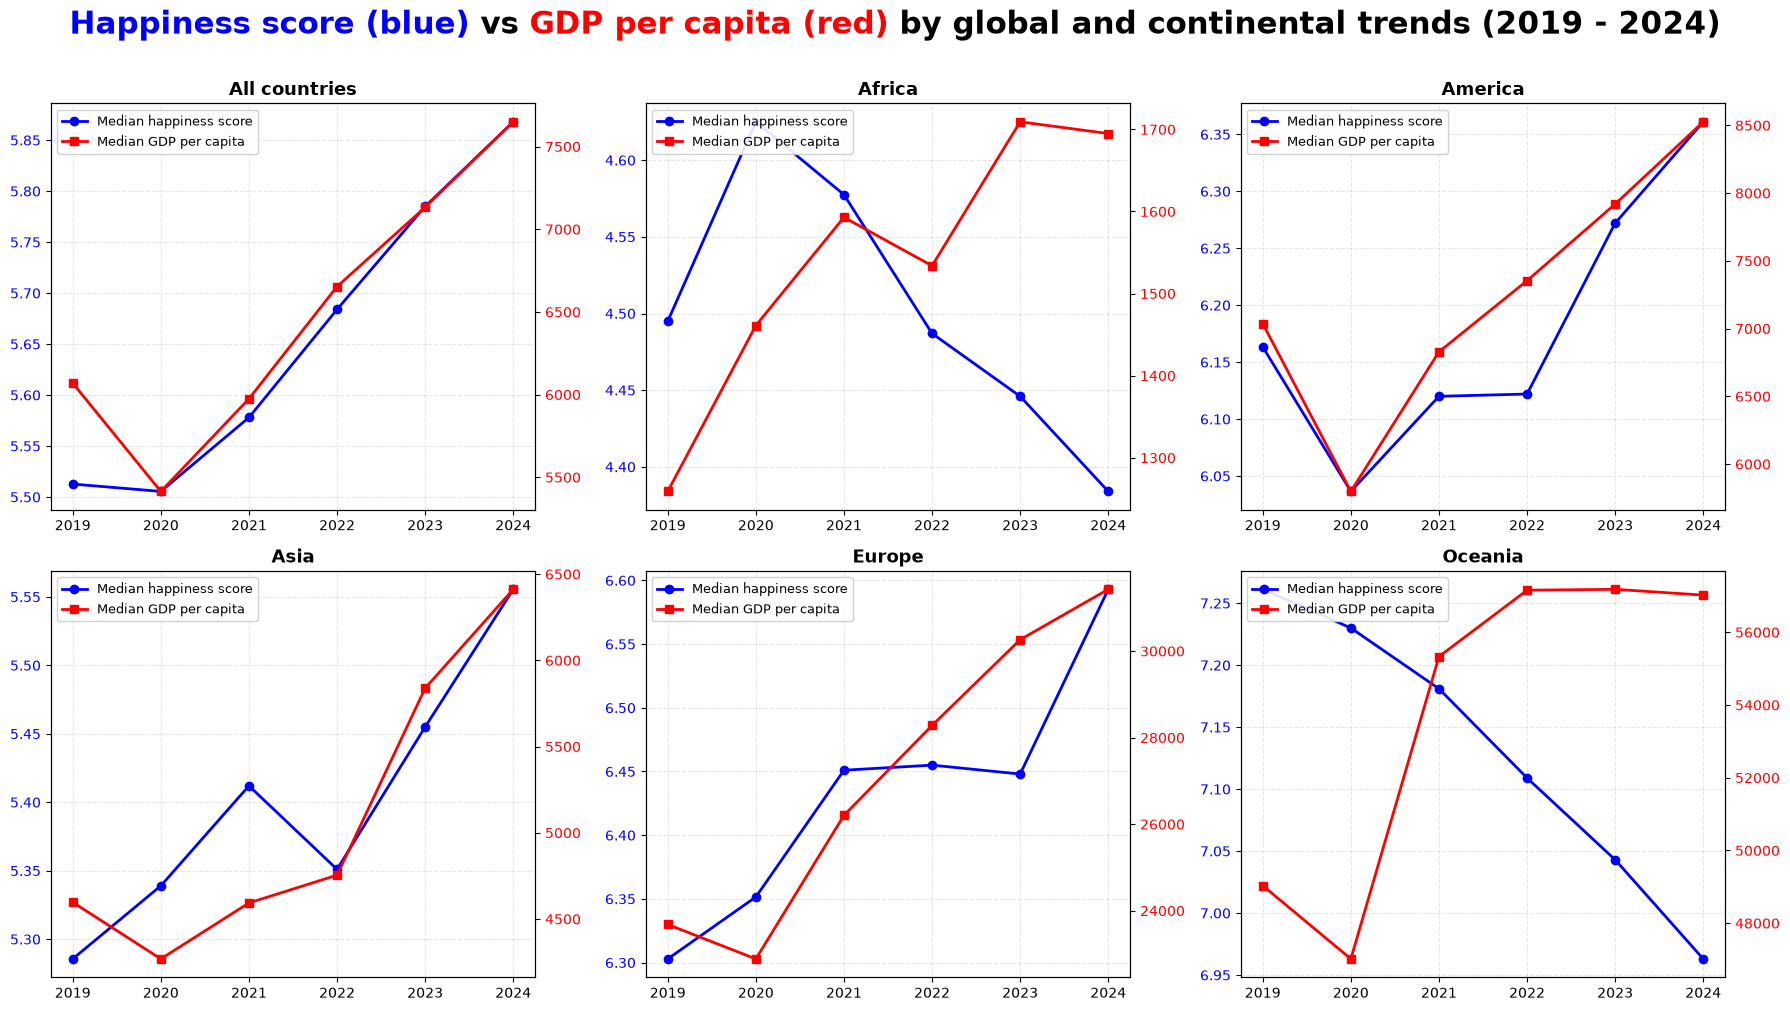

In [15]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea

# 1. Initialize 2-row x 3-column subplot grid
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

color_score = 'blue'  # Professional Blue
color_gdp = 'red'  # Professional Red


global_df = merged.groupby('year')[['score', 'gdp_pc']].median().reset_index()
ax_global_1 = axes[0]

# Left Y-Axis: Global Score
line1 = ax_global_1.plot(
    global_df['year'],
    global_df['score'],
    color=color_score,
    marker='o',
    linewidth=2,
    label='Median happiness score',
)
ax_global_1.tick_params(axis='y', labelcolor=color_score)
ax_global_1.set_xticks(global_df['year'].unique())
ax_global_1.set_title('All countries', fontsize=13, fontweight='bold')
ax_global_1.grid(True, linestyle='--', alpha=0.3)

# Right Y-Axis: Global GDP per Capita
ax_global_2 = ax_global_1.twinx()
line2 = ax_global_2.plot(
    global_df['year'],
    global_df['gdp_pc'],
    color=color_gdp,
    marker='s',
    linewidth=2,
    label='Median GDP per capita',
)
ax_global_2.tick_params(axis='y', labelcolor=color_gdp)

# Legend for Global Subplot
lines_g = line1 + line2
labels_g = [l.get_label() for l in lines_g]
ax_global_1.legend(
    lines_g, labels_g, loc='upper left', fontsize=9, framealpha=0.9
)


continent_df = (
    merged.groupby(['continent', 'year'])[['score', 'gdp_pc']].median().reset_index()
)
continents = sorted(continent_df['continent'].dropna().unique())

for i, continent in enumerate(continents):
  ax_idx = i + 1  # Shifts by 1 to keep Global at top-left (index 0)
  if ax_idx >= len(axes):
    break

  ax1 = axes[ax_idx]
  subset = continent_df[continent_df['continent'] == continent]

  # Left Y-Axis: Continent Score
  l1 = ax1.plot(
      subset['year'],
      subset['score'],
      color=color_score,
      marker='o',
      linewidth=2,
      label='Median happiness score',
  )
  ax1.tick_params(axis='y', labelcolor=color_score)
  ax1.set_xticks(subset['year'].unique())
  ax1.set_title(continent, fontsize=13, fontweight='bold')
  ax1.grid(True, linestyle='--', alpha=0.3)

  # Right Y-Axis: Continent GDP per Capita
  ax2 = ax1.twinx()
  l2 = ax2.plot(
      subset['year'],
      subset['gdp_pc'],
      color=color_gdp,
      marker='s',
      linewidth=2,
      label='Median GDP per capita',
  )
  ax2.tick_params(axis='y', labelcolor=color_gdp)

  # Legend for Continent Subplots
  lines = l1 + l2
  labels = [l.get_label() for l in lines]
  ax1.legend(lines, labels, loc='upper left', fontsize=9, framealpha=0.9)

# Clean up any unused subplots if continent count is less than 5
for j in range(len(continents) + 1, len(axes)):
  fig.delaxes(axes[j])

t1 = TextArea(
    'Happiness score (blue) ',
    textprops=dict(color=color_score, fontsize=22, fontweight='bold'),
)
t2 = TextArea(
    'vs ', textprops=dict(color='black', fontsize=22, fontweight='bold')
)
t3 = TextArea(
    'GDP per capita (red) ',
    textprops=dict(color=color_gdp, fontsize=22, fontweight='bold'),
)
t4 = TextArea(
    'by global and continental trends (2019 - 2024)',
    textprops=dict(color='black', fontsize=22, fontweight='bold'),
)

title_box = HPacker(pad=0, sep=0, children=[t1, t2, t3, t4], align='baseline')

anchored_title = AnchoredOffsetbox(
    loc='lower center',
    child=title_box,
    pad=0.0,
    frameon=False,
    bbox_to_anchor=(0.5, 0.975),
    bbox_transform=fig.transFigure,
    borderpad=0.0,
)

fig.add_artist(anchored_title)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Slide 10: income growth vs change in happiness

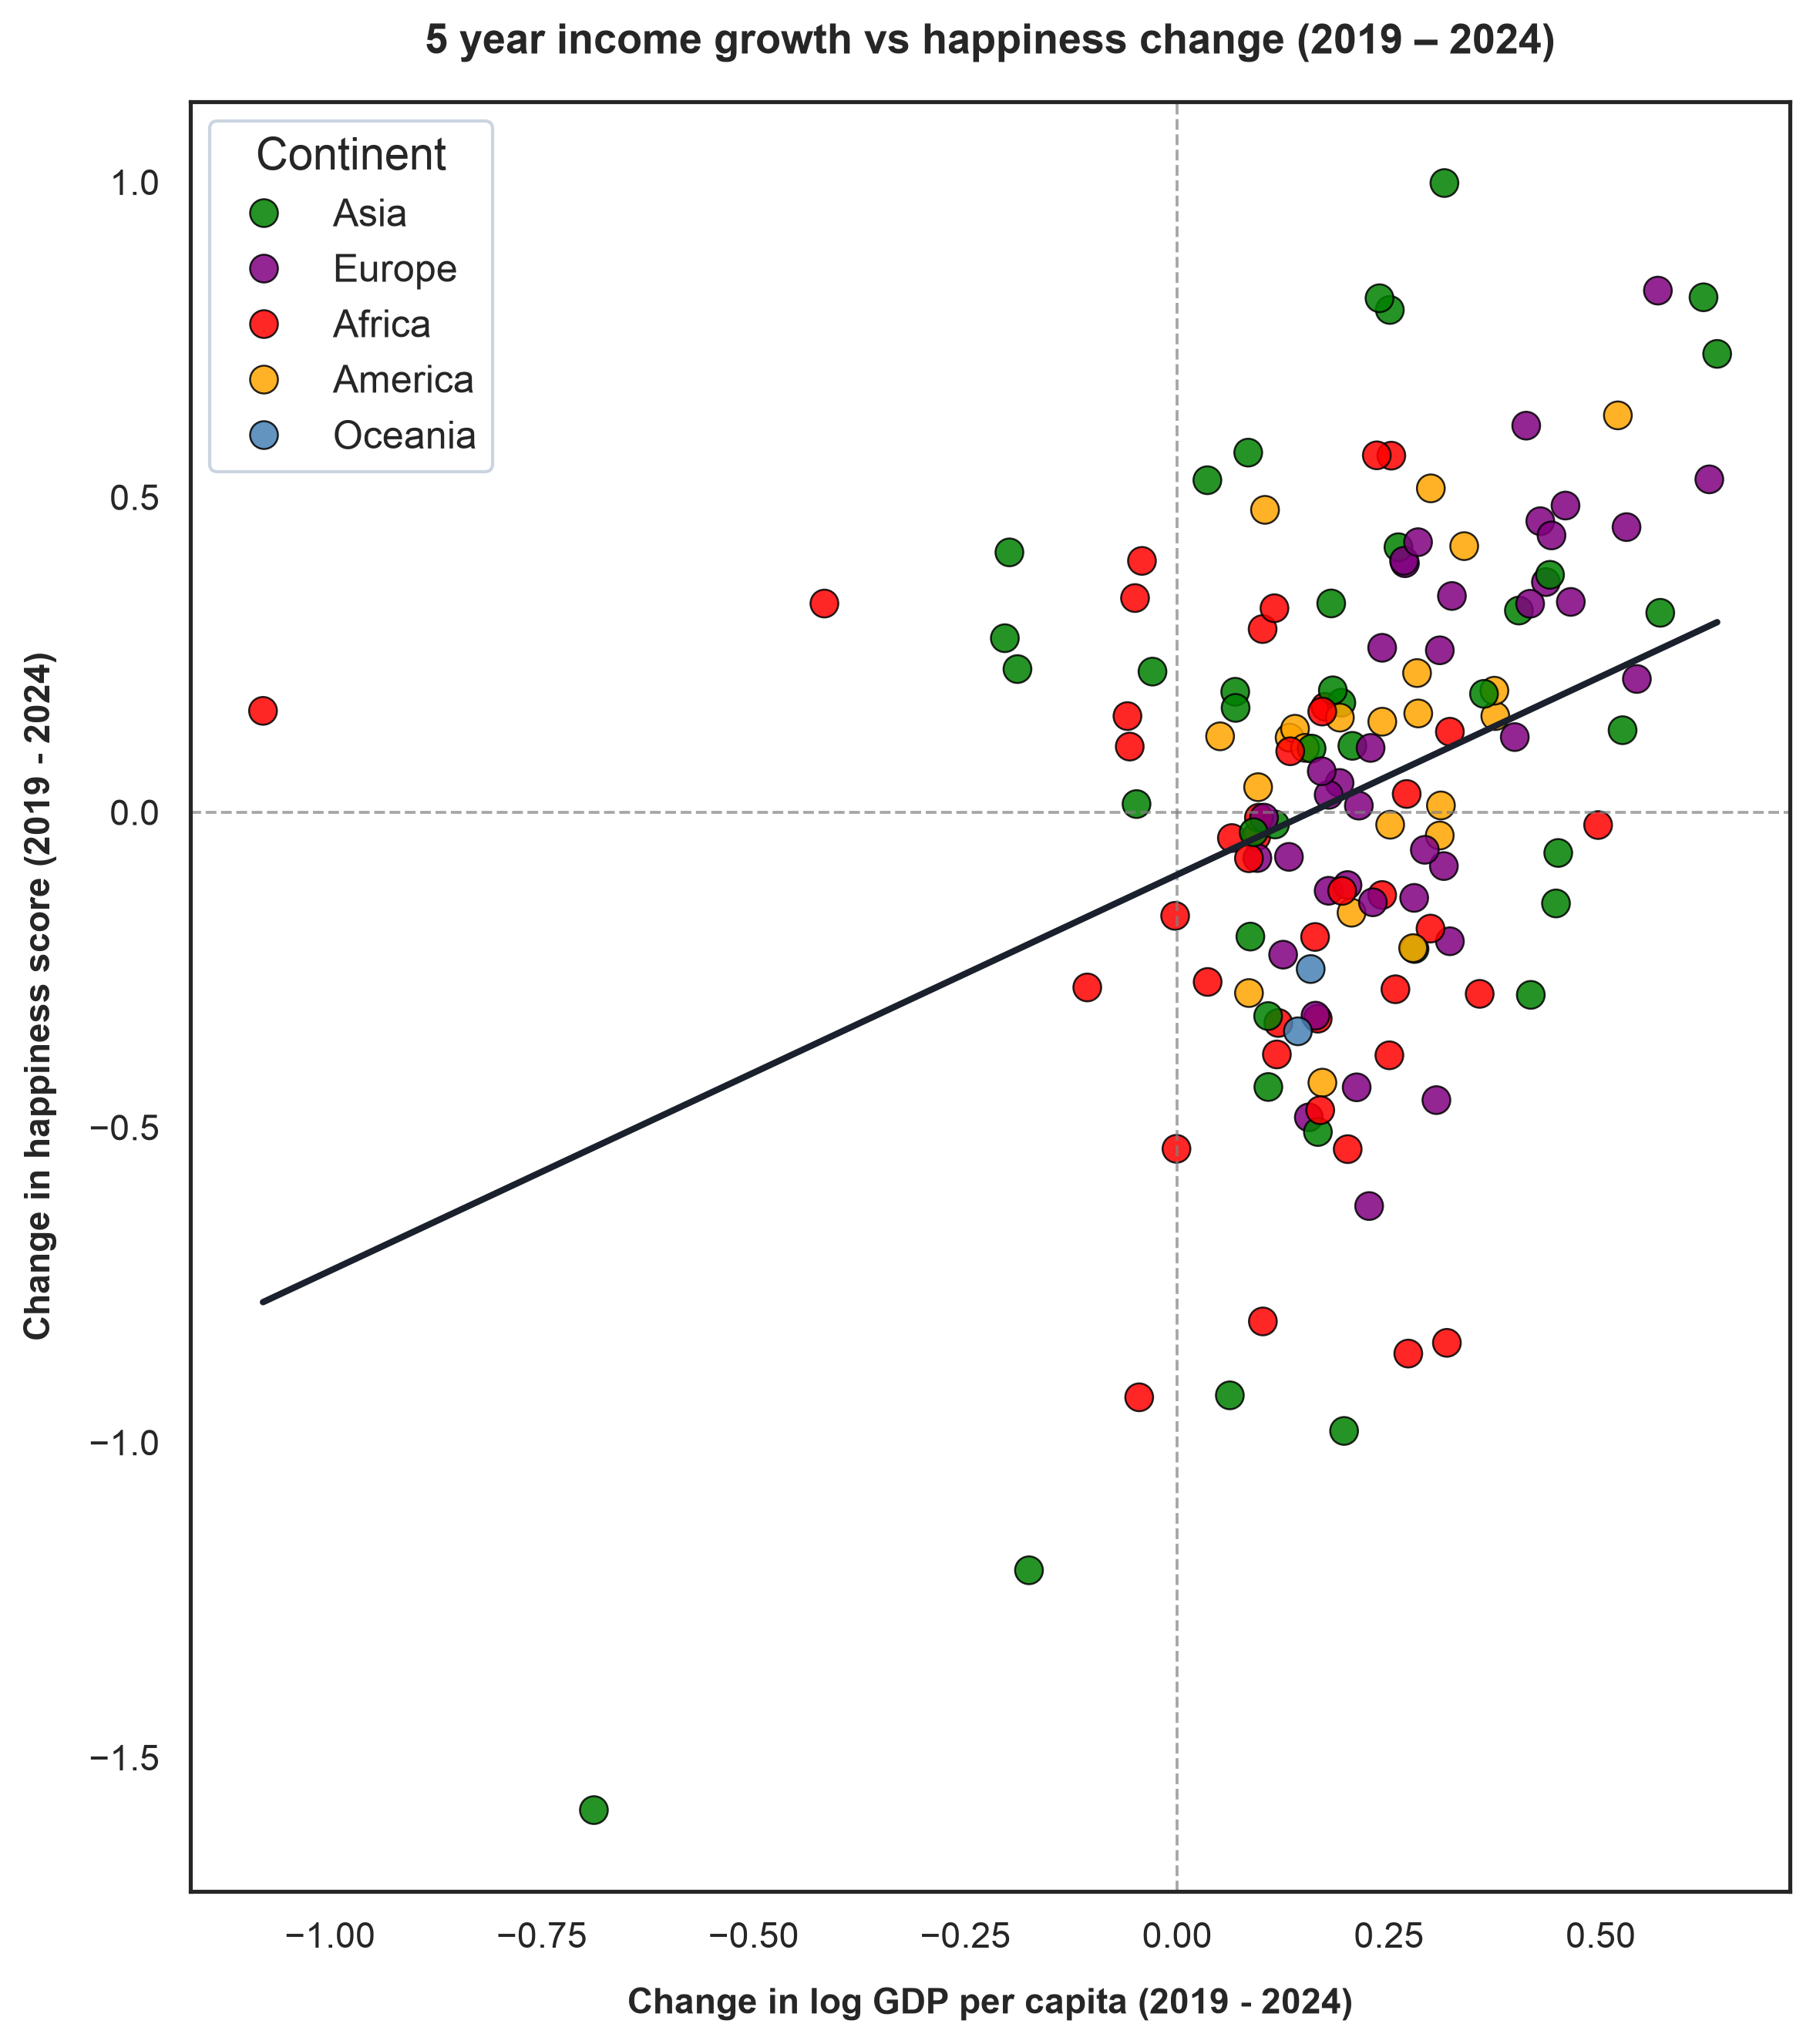

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Clean white presentation styling (no background grid bleed)
sns.set_theme(style='white')

df_19 = merged[merged['year'] == 2019].set_index('country')
df_24 = merged[merged['year'] == 2024].set_index('country')

# 2. Compute 5-year changes (2019 -> 2024) and retain continent
delta = pd.DataFrame({
    'delta_score': df_24['score'] - df_19['score'],
    'delta_log_gdp': np.log(df_24['gdp_pc']) - np.log(df_19['gdp_pc']),
    'continent': df_24['continent'],
}).dropna()

# 3. Canvas setup with widescreen (16:9 proportion friendly)
fig, ax = plt.subplots(figsize=(8, 9), dpi=300)
ax.grid(False)

# Reference zero-lines dividing the 4 quadrants
ax.axhline(0, color='gray', linestyle='--', linewidth=0.9, alpha=0.7)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.9, alpha=0.7)

# High-contrast palette for projector visibility
continent_colors = {
    'Africa': 'red',
    'America': 'Orange',
    'Asia': 'green',
    'Europe': 'purple',
    'Oceania': 'Steelblue',
}

# 4. Scatter plot colored by continent
sns.scatterplot(
    data=delta,
    x='delta_log_gdp',
    y='delta_score',
    hue='continent',
    palette=continent_colors,
    s=75,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.6,
    ax=ax,
)

# 5. Global linear regression trend line
m, b = np.polyfit(delta['delta_log_gdp'], delta['delta_score'], 1)
x_vals = np.linspace(
    delta['delta_log_gdp'].min(), delta['delta_log_gdp'].max(), 100
)
ax.plot(
    x_vals,
    m * x_vals + b,
    color='#1a202c',
    linestyle='-',
    linewidth=2
)

# 6. Labels and presentation typography
ax.set_title(
    '5 year income growth vs happiness change (2019 – 2024)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel(
    'Change in log GDP per capita (2019 - 2024)',
    fontsize=11,
    fontweight='bold',
    labelpad=10,
)
ax.set_ylabel(
    'Change in happiness score (2019 - 2024)',
    fontsize=11,
    fontweight='bold',
    labelpad=10,
)

# Place legend inside the top-left corner with a slight white background box
ax.legend(
    title='Continent',
    loc='upper left',
    frameon=True,
    facecolor='white',
    framealpha=1,
    edgecolor='#cbd5e1',
    fontsize=12,
    title_fontsize=14,
)

plt.tight_layout()
plt.show()

Share of each continent in each quadrant

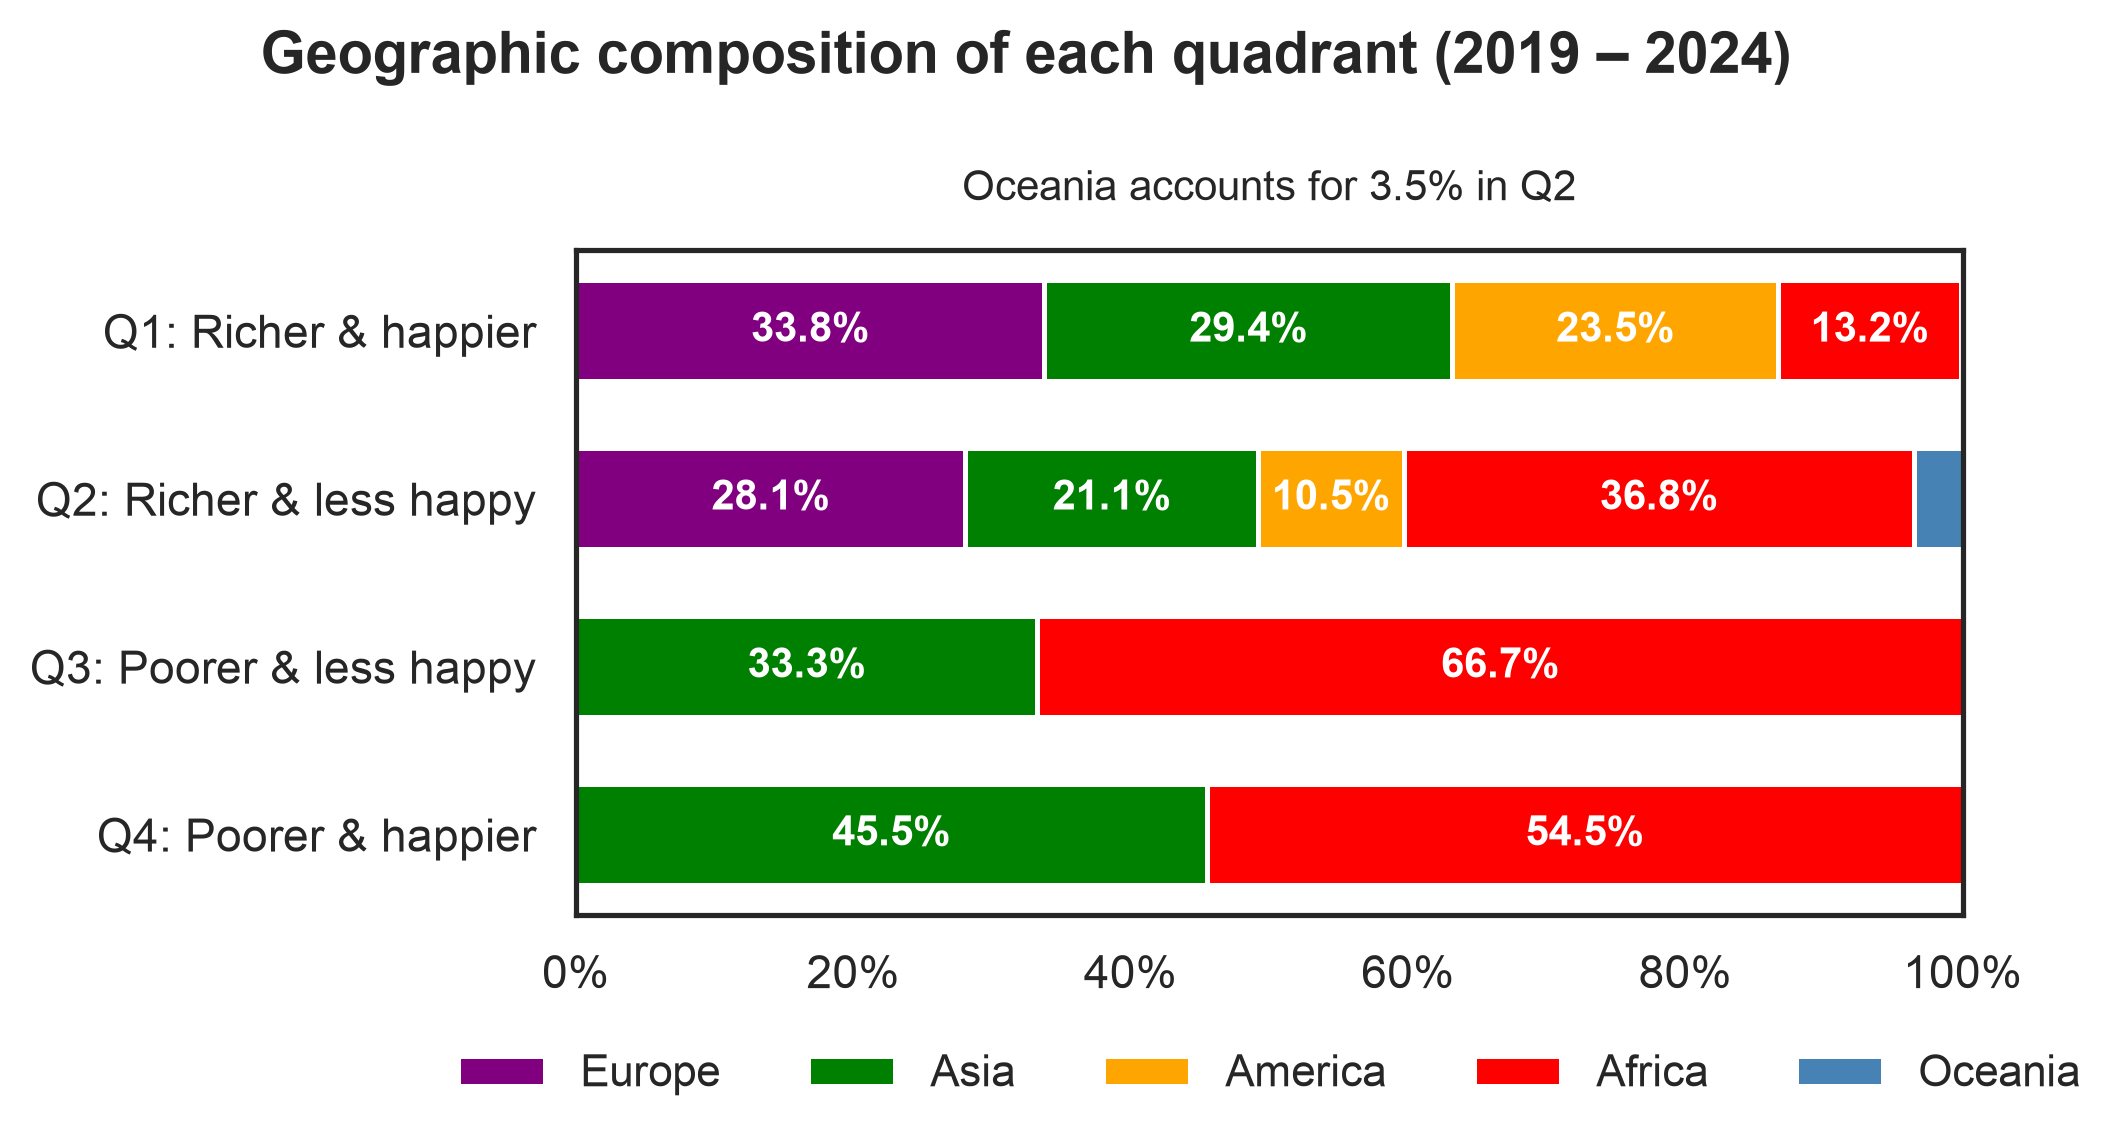

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Data from Table 3
t3_data = {
    'Quadrant': [
        'Q1: Richer & happier',
        'Q2: Richer & less happy',
        'Q3: Poorer & less happy',
        'Q4: Poorer & happier'
    ],
    'Europe': [33.8, 28.1, 0.0, 0.0],
    'Asia': [29.4, 21.1, 33.3, 45.5],
    'America': [23.5, 10.5, 0.0, 0.0],
    'Africa': [13.2, 36.8, 66.7, 54.5],
    'Oceania': [0.0, 3.5, 0.0, 0.0],
}
df_t3 = pd.DataFrame(t3_data).set_index('Quadrant')

fig, ax = plt.subplots(figsize=(7, 4), dpi=300)
sns.set_theme(style='white')
ax.grid(False)

# Continent palette matching the scatter plot
c_colors = {
    'Europe': 'purple',  # Purple
    'Asia': 'green',  # Green
    'America': 'orange',  # Orange
    'Africa': 'red',  # Red
    'Oceania': 'steelblue',  # Steelblue
}

left = np.zeros(len(df_t3))
for col in df_t3.columns:
  values = df_t3[col].values
  ax.barh(
      df_t3.index,
      values,
      left=left,
      color=c_colors[col],
      label=col,
      edgecolor='white',
      height=0.6,
      linewidth=1.2,
  )

  for i, val in enumerate(values):
    if val >= 4.0:
      ax.text(
          left[i] + val / 2.0,
          i,
          f'{val:.1f}%',
          ha='center',
          va='center',
          color='white',
          fontweight='bold',
          fontsize=10,
      )
  left += values

ax.set_xlim(0, 100)

# Removed x-axis label
ax.set_xlabel('')

# Main Title & Subtitle for Oceania
plt.suptitle(
    'Geographic composition of each quadrant (2019 – 2024)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
ax.set_title(
    'Oceania accounts for 3.5% in Q2',
    fontsize=10,
    pad=12,
)

ax.xaxis.set_major_formatter('{x:.0f}%')
ax.tick_params(axis='both', labelsize=11)
plt.gca().invert_yaxis()

# Legend without the "Continent" title
ax.legend(
    bbox_to_anchor=(0.5, -0.15),
    loc='upper center',
    ncol=5,
    frameon=False,
    fontsize=10.5,
    title=None,
)

plt.tight_layout()
plt.savefig(OUT /'plot_table3_quadrant_composition.png', dpi=300, bbox_inches='tight')
plt.show()

Summary of the four quadrants

findfont: Failed to find font weight semibold for Arial, now using 700.


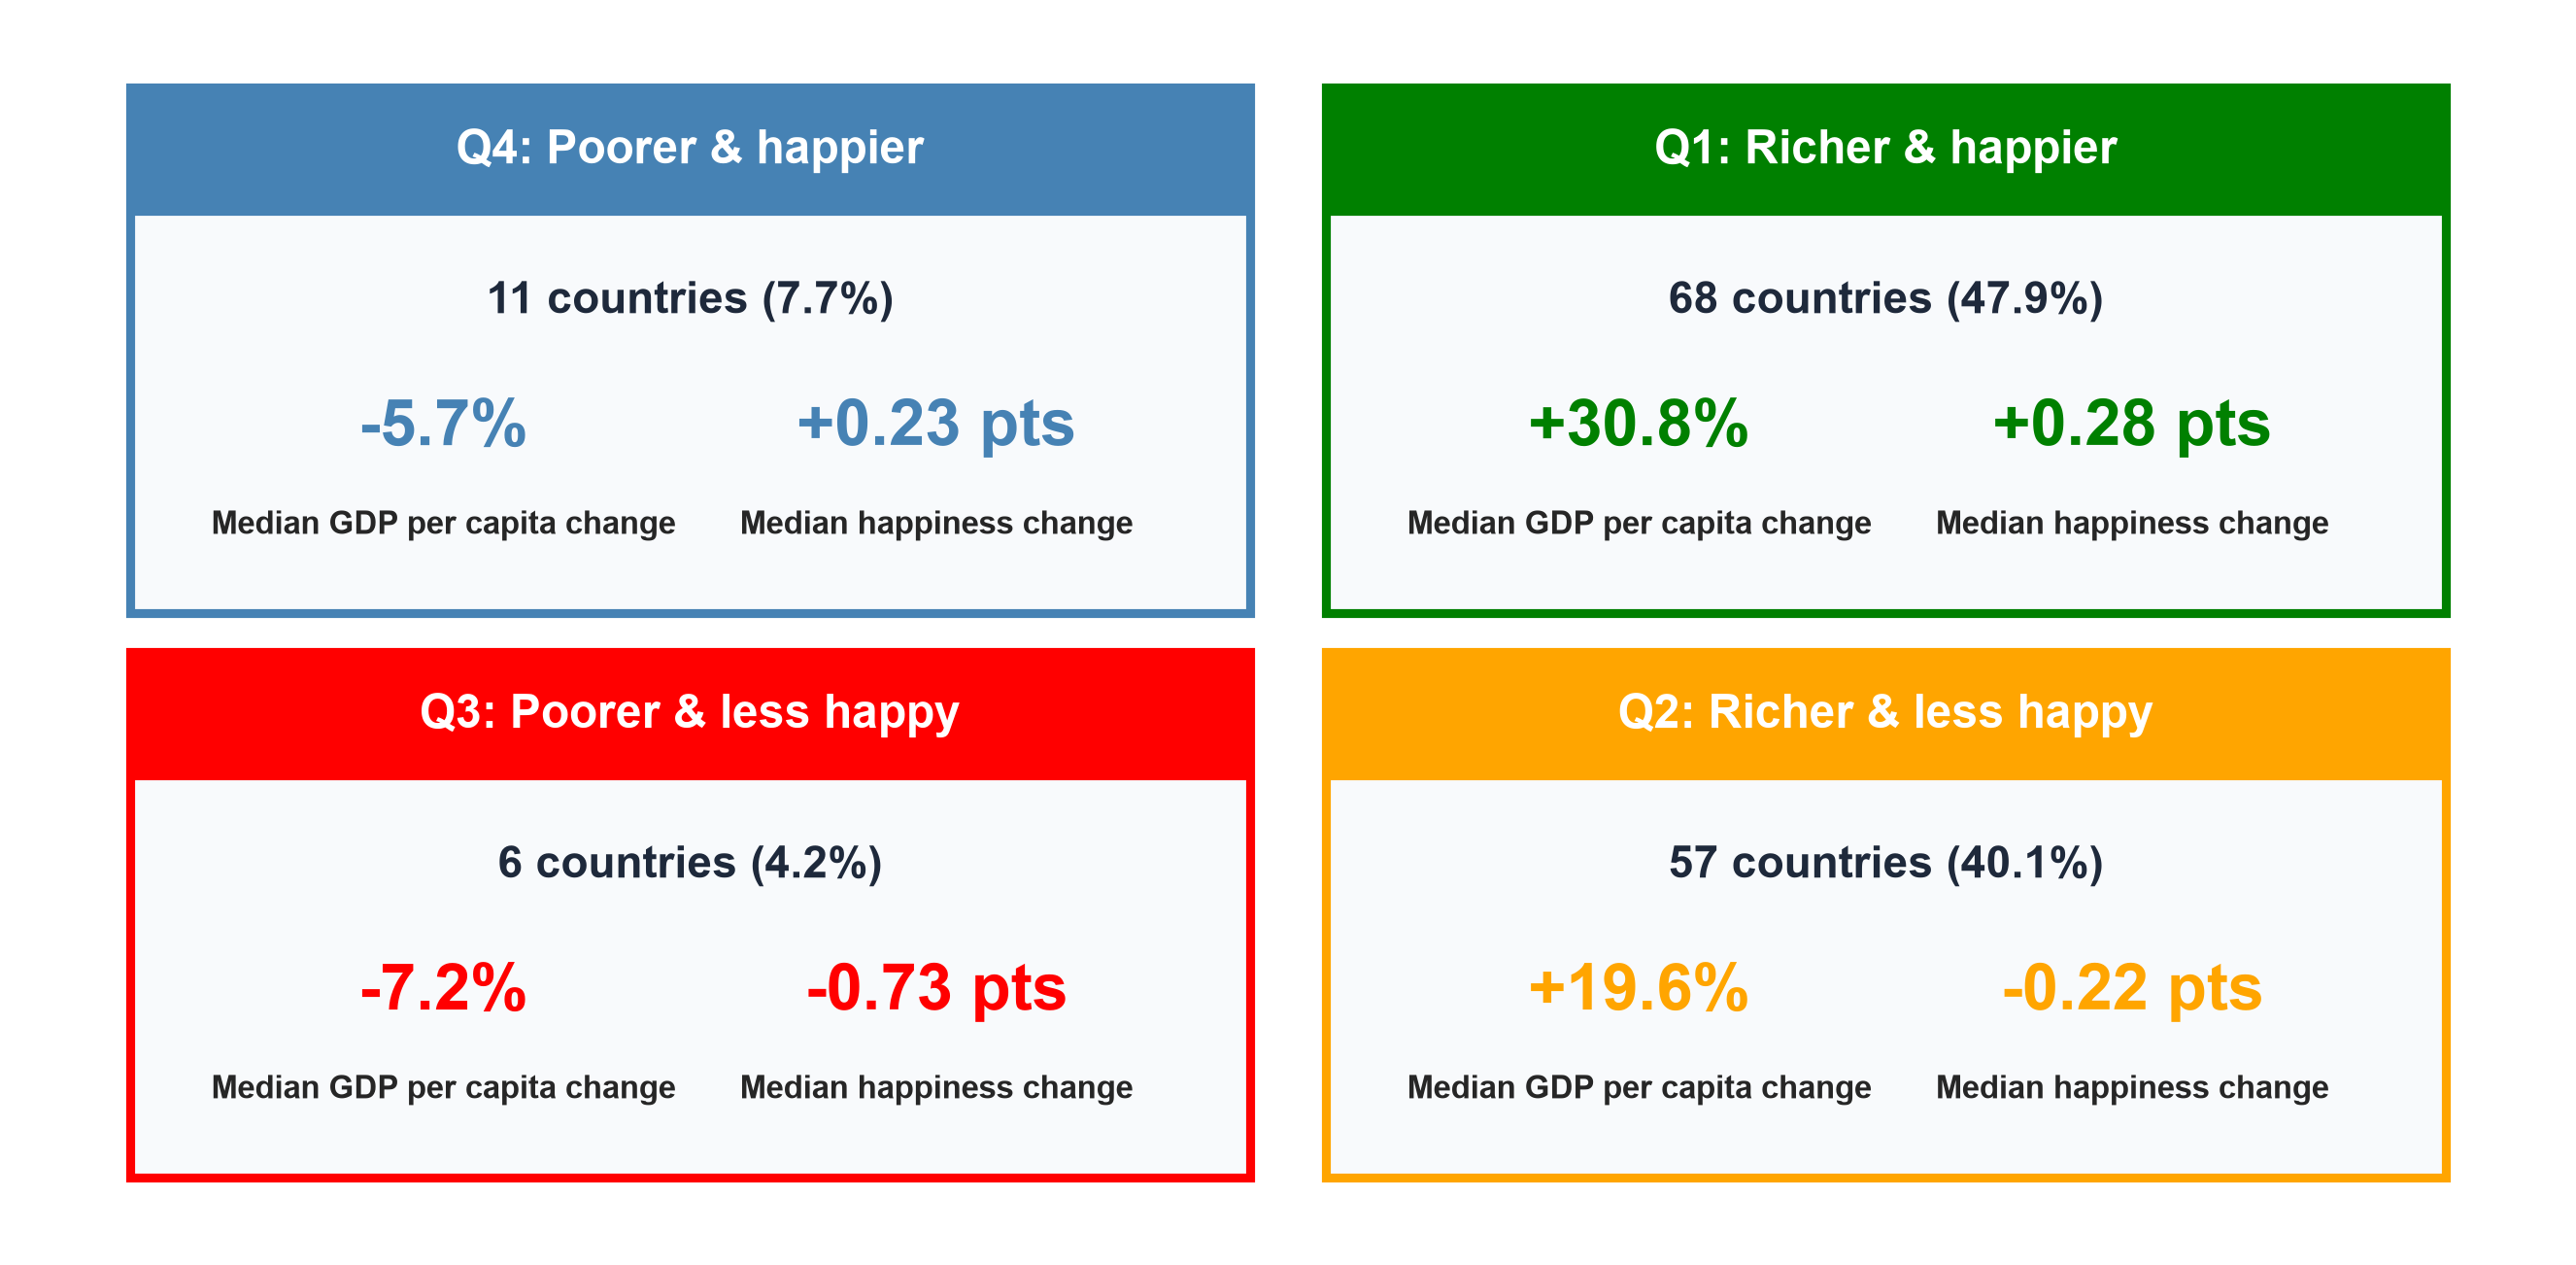

In [18]:
import matplotlib.pyplot as plt

# Compact 2x2 matrix layout with reduced outer gaps and inner padding
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
ax.set_xlim(0, 10)
ax.set_ylim(0, 6.2)
ax.axis('off')

# Quadrant brand colors
colors = {
    'Q1': 'green',  # Forest Green
    'Q2': 'orange',  # Vibrant Orange
    'Q3': 'red',  # Dark Crimson
    'Q4': 'steelblue',  # Sky Blue
}

# 2x2 card layout: closer together (gap reduced from 0.6 to 0.3) & shorter cards (height 2.7 instead of 4.0)
cards = {
    'Q4': {
        'rect': [0.4, 3.2, 4.45, 2.7],
        'color': colors['Q4'],
        'title': 'Q4: Poorer & happier',
        'n': '11 countries (7.7%)',
        'gdp': '-5.7%',
        'score': '+0.23 pts',
    },
    'Q1': {
        'rect': [5.15, 3.2, 4.45, 2.7],
        'color': colors['Q1'],
        'title': 'Q1: Richer & happier',
        'n': '68 countries (47.9%)',
        'gdp': '+30.8%',
        'score': '+0.28 pts',
    },
    'Q3': {
        'rect': [0.4, 0.3, 4.45, 2.7],
        'color': colors['Q3'],
        'title': 'Q3: Poorer & less happy',
        'n': '6 countries (4.2%)',
        'gdp': '-7.2%',
        'score': '-0.73 pts',
    },
    'Q2': {
        'rect': [5.15, 0.3, 4.45, 2.7],
        'color': colors['Q2'],
        'title': 'Q2: Richer & less happy',
        'n': '57 countries (40.1%)',
        'gdp': '+19.6%',
        'score': '-0.22 pts',
    },
}

for q, info in cards.items():
  r, c = info['rect'], info['color']

  # Outer card background
  bbox = plt.Rectangle(
      (r[0], r[1]),
      r[2],
      r[3],
      facecolor='#f8fafc',
      edgecolor=c,
      linewidth=2.2,
  )
  ax.add_patch(bbox)

  # Compact header badge
  header_h = 0.65
  header = plt.Rectangle(
      (r[0], r[1] + r[3] - header_h), r[2], header_h, facecolor=c, edgecolor=c
  )
  ax.add_patch(header)
  ax.text(
      r[0] + r[2] / 2,
      r[1] + r[3] - header_h / 2,
      info['title'],
      ha='center',
      va='center',
      color='white',
      fontsize=11.5,
      fontweight='bold',
  )

  # Sample Size
  ax.text(
      r[0] + r[2] / 2,
      r[1] + r[3] - 1.1,
      info['n'],
      ha='center',
      va='center',
      color='#1e293b',
      fontsize=11,
      fontweight='bold',
  )

  # Metrics positioning
  metric_y = r[1] + 0.95
  label_y = r[1] + 0.45

  ax.text(
      r[0] + r[2] * 0.28,
      metric_y,
      info['gdp'],
      ha='center',
      va='center',
      color=c,
      fontsize=16,
      fontweight='bold',
  )
  ax.text(
      r[0] + r[2] * 0.28,
      label_y,
      'Median GDP per capita change',
      ha='center',
      va='center',
      fontsize=8,
      fontweight='semibold',
  )

  ax.text(
      r[0] + r[2] * 0.72,
      metric_y,
      info['score'],
      ha='center',
      va='center',
      color=c,
      fontsize=16,
      fontweight='bold',
  )
  ax.text(
      r[0] + r[2] * 0.72,
      label_y,
      'Median happiness change',
      ha='center',
      va='center',
      fontsize=8,
      fontweight='semibold',
  )



plt.tight_layout()
plt.show()

In [19]:
df_19 = merged[merged['year'] == 2019].set_index('country')
df_24 = merged[merged['year'] == 2024].set_index('country')

delta = pd.DataFrame({
    'delta_score': df_24['score'] - df_19['score'],
    'delta_log_gdp': np.log(df_24['gdp_pc']) - np.log(df_19['gdp_pc']),
    'continent': df_24['continent'],
}).dropna()


def assign_quadrant(row):
  if row['delta_log_gdp'] >= 0 and row['delta_score'] >= 0:
    return 'Q1: Richer & happier'
  elif row['delta_log_gdp'] >= 0 and row['delta_score'] < 0:
    return 'Q2: Richer & less happy'
  elif row['delta_log_gdp'] < 0 and row['delta_score'] < 0:
    return 'Q3: Poorer & less happy'
  else:
    return 'Q4: Poorer & happier'


delta['quadrant'] = delta.apply(assign_quadrant, axis=1)

quadrant_order = [
    'Q1: Richer & happier',
    'Q2: Richer & less happy',
    'Q3: Poorer & less happy',
    'Q4: Poorer & happier',]

for q in quadrant_order:
  countries = sorted(delta[delta['quadrant'] == q].index.tolist())
  print(f'{q} (Count: {len(countries)})')
  print(', '.join(countries))

q3_detail = (
    delta[delta['quadrant'] == 'Q3: Poorer & less happy']
    .sort_values(by='delta_score')[['continent', 'delta_score', 'delta_log_gdp']]
    .round(3))

print('Q3 Countries')
print(q3_detail)

Q1: Richer & happier (Count: 68)
Albania, Algeria, Argentina, Armenia, Belgium, Bolivia, Bosnia and Herzegovina, Brazil, Bulgaria, Chile, China, Costa Rica, Croatia, Dominican Republic, Ecuador, El Salvador, Estonia, Gabon, Georgia, Greece, Honduras, Iceland, India, Indonesia, Iran, Iraq, Israel, Italy, Kazakhstan, Kosovo, Kuwait, Kyrgyzstan, Latvia, Lithuania, Malaysia, Mauritania, Mexico, Mongolia, Montenegro, Mozambique, Nepal, Nicaragua, North Macedonia, Panama, Paraguay, Peru, Philippines, Poland, Portugal, Republic of Korea, Republic of Moldova, Romania, Russian Federation, Saudi Arabia, Serbia, Singapore, Slovenia, Spain, Tanzania, Togo, Tunisia, Türkiye, Uganda, Ukraine, Uruguay, Venezuela, Viet Nam, Zimbabwe
Q2: Richer & less happy (Count: 57)
Australia, Austria, Azerbaijan, Bahrain, Bangladesh, Benin, Botswana, Burkina Faso, Cambodia, Cameroon, Canada, Chad, Colombia, Comoros, Cyprus, Czechia, Côte d’Ivoire, DR Congo, Denmark, Egypt, Ethiopia, Finland, France, Gambia, Germany

### Slide 11: map of the quadrants

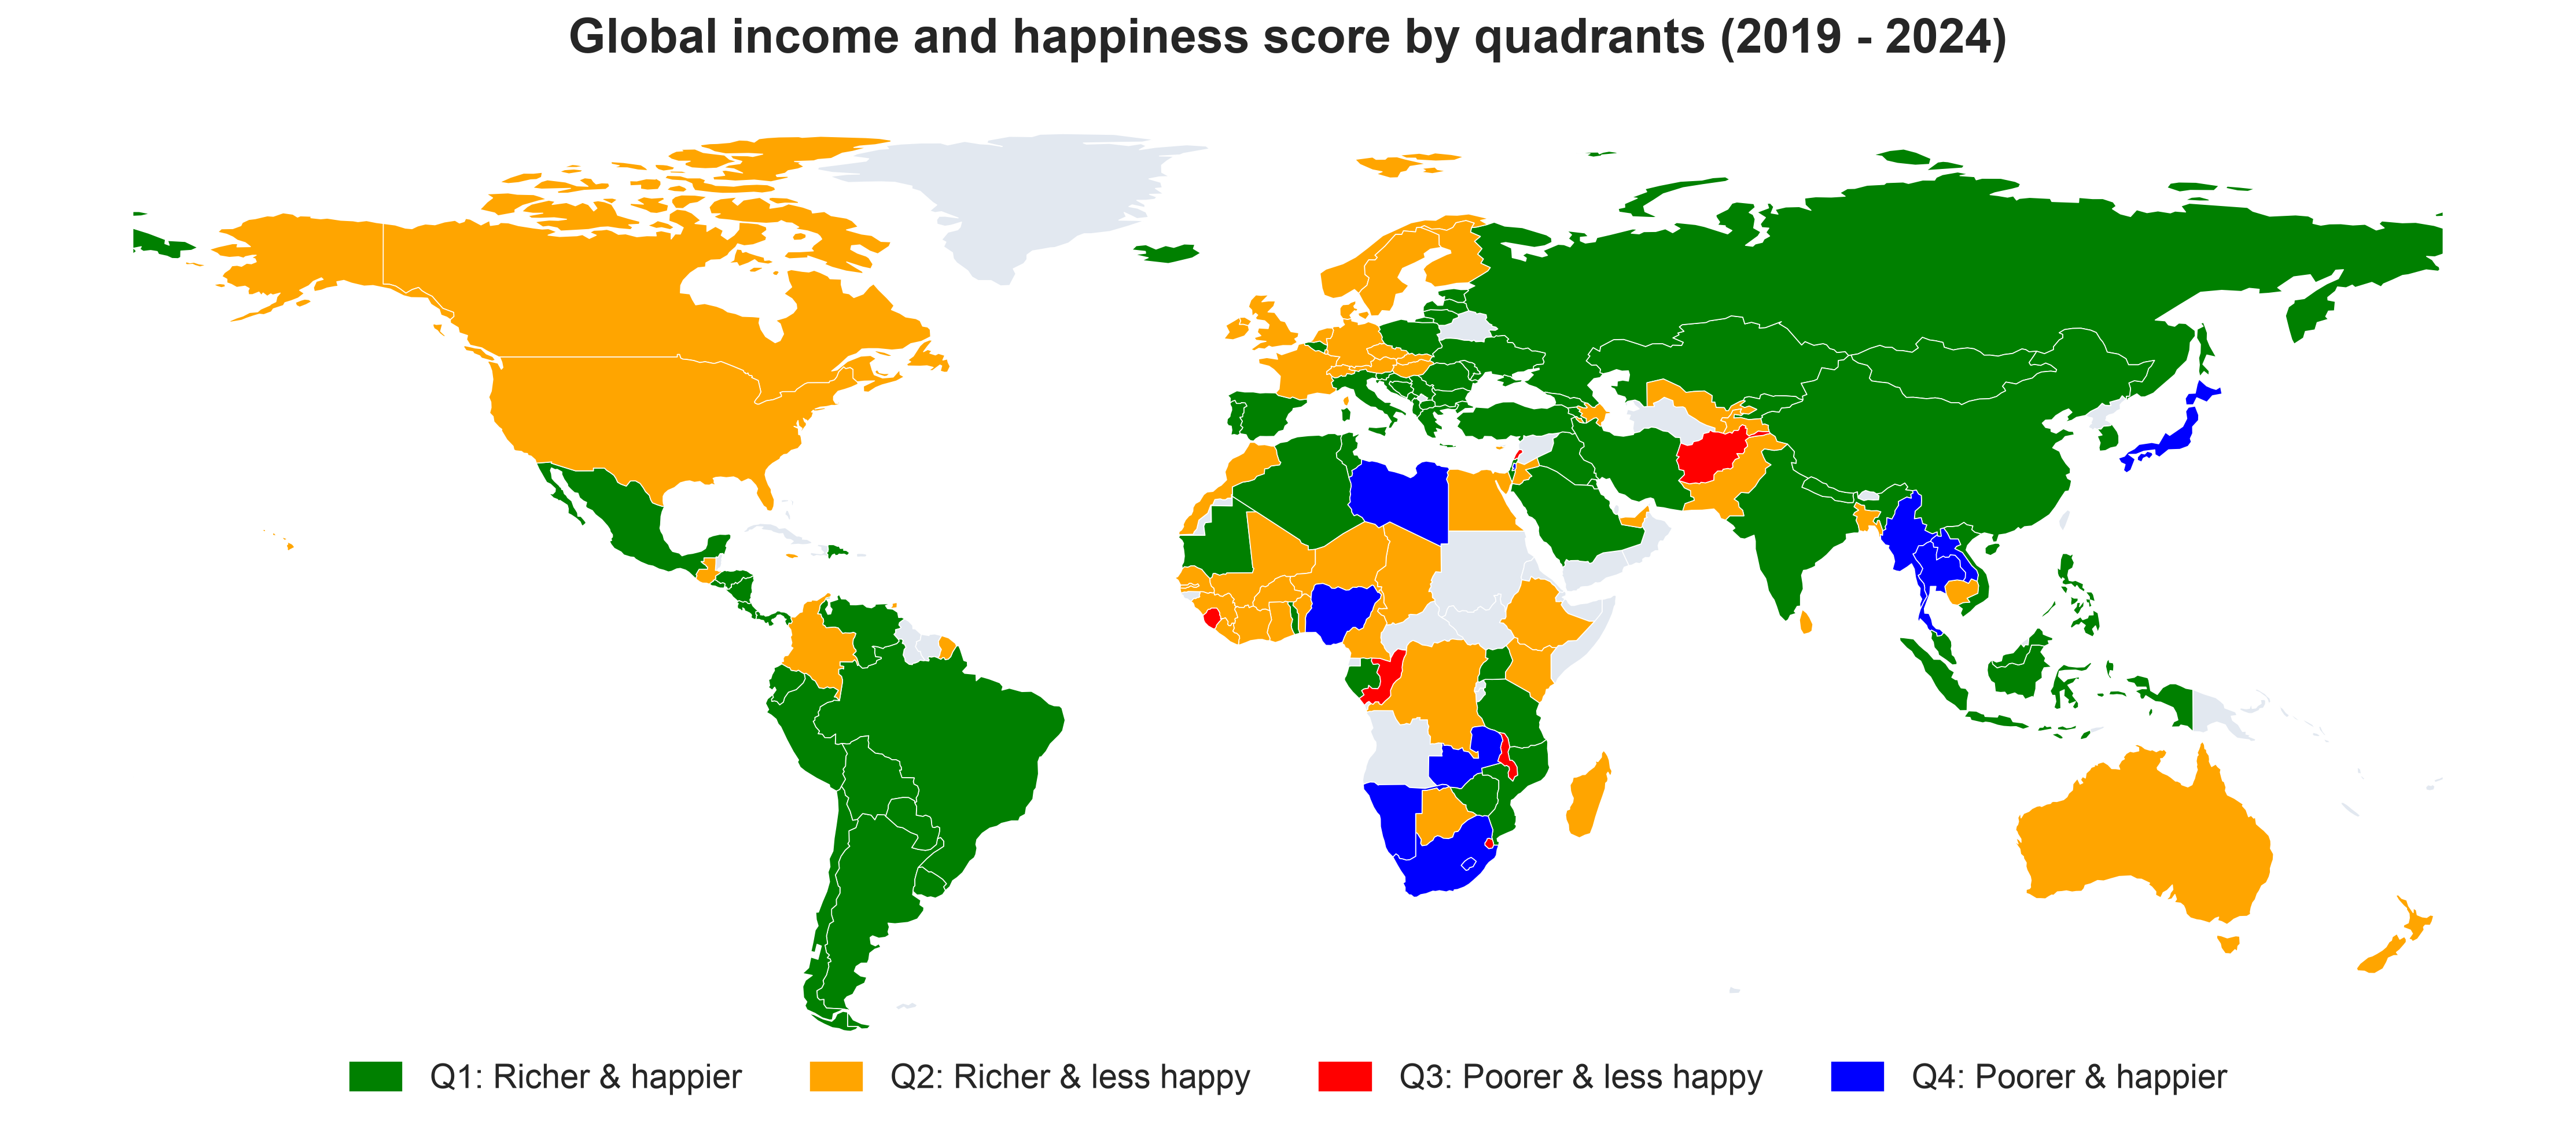

In [20]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Compute 5-year deltas (2019 to 2024)
df_19 = merged[merged['year'] == 2019].set_index('country')
df_24 = merged[merged['year'] == 2024].set_index('country')

delta = pd.DataFrame({
    'delta_score': df_24['score'] - df_19['score'],
    'delta_log_gdp': np.log(df_24['gdp_pc']) - np.log(df_19['gdp_pc']),
    'iso3': df_24['iso3'],
}).dropna()


# 2. Assign the 4 Quadrants
def assign_quadrant(row):
  if row['delta_log_gdp'] >= 0 and row['delta_score'] >= 0:
    return 'Q1: Richer & happier'
  elif row['delta_log_gdp'] >= 0 and row['delta_score'] < 0:
    return 'Q2: Richer & less happy'
  elif row['delta_log_gdp'] < 0 and row['delta_score'] < 0:
    return 'Q3: Poorer & less happy'
  else:
    return 'Q4: Poorer & happier'


delta['quadrant'] = delta.apply(assign_quadrant, axis=1)

# 3. Load Natural Earth GeoJSON (GeoPandas 1.0+ compatible)
world_url = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson'
world = gpd.read_file(world_url)
world = world[world['ADM0_A3'] != 'ATA']  # Exclude Antarctica

world['iso_code'] = (
    world['ISO_A3'].replace('-99', np.nan).fillna(world['ADM0_A3'])
)
world_mapped = world.merge(
    delta, left_on='iso_code', right_on='iso3', how='left'
)

# 4. Canvas Setup
fig, ax = plt.subplots(figsize=(15, 7.5), dpi=300)
ax.set_facecolor('#ffffff')

# Layer 1: Base world map (countries outside dataset colored light grey)
world.plot(ax=ax, color='#e2e8f0', edgecolor='#ffffff', linewidth=0.4)

# Layer 2: Quadrant color layers
quad_colors = {
    'Q1: Richer & happier': 'green',  # Forest Green
    'Q2: Richer & less happy': 'orange',  # Deep Amber / Orange
    'Q3: Poorer & less happy': 'red',  # Crimson Red
    'Q4: Poorer & happier': 'blue',  # Rich Blue
}

for quad, color in quad_colors.items():
  subset = world_mapped[world_mapped['quadrant'] == quad]
  if not subset.empty:
    subset.plot(
        ax=ax, color=color, edgecolor='#ffffff', linewidth=0.4, label=quad
    )

# --- REMOVE GEODETIC LATITUDE & LONGITUDE TEXT ---
ax.set_xlabel('')
ax.set_ylabel('')
ax.axis('off')  # Completely hides map boundary lines, ticks, and axis labels

# Title
plt.title(
    'Global income and happiness score by quadrants (2019 - 2024)',
    fontsize=20,
    fontweight='bold',
    pad=15,
)

# --- ENLARGED LEGEND ---
ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=4,
    frameon=False,
    fontsize=14,  # Increased font size for clarity on slides
    handlelength=1.6,  # Slightly wider color swatches
    handleheight=1.0,
    columnspacing=2.0,  # Breathing room between legend items
)

plt.tight_layout()
plt.show()

## Income and happiness 
2024 score against log GDP per capita (PPP), with a straight line fit.
The gap is the score minus the score predicted by the line, so a positive gap means happier than income predicts.

In [21]:
inc = merged[merged["year"] == 2024].dropna(subset=["score", "gdp_ppp"]).copy()
inc["ln_ppp"] = np.log(inc["gdp_ppp"])

slope, intercept = np.polyfit(inc["ln_ppp"], inc["score"], 1)
inc["fit"] = intercept + slope * inc["ln_ppp"]
inc["gap"] = inc["score"] - inc["fit"]
inc["hw"] = (inc["hi"] - inc["lo"]) / 2          # half width of the 95% interval
inc["group"] = np.where(inc["gap"] > 0, "Happier than predicted", "Less happy than predicted")

r2 = np.corrcoef(inc["ln_ppp"], inc["score"])[0, 1] ** 2
print(round(r2, 2), len(inc))
print("points per doubling of income:", round(slope * np.log(2), 2))
print("std of the gap:", round(inc["gap"].std(), 2))

cols = ["country", "iso3", "region", "score", "lo", "hi", "gdp_ppp", "fit", "gap", "hw", "group"]
inc[cols].round(3).to_csv(OUT / "flourish_scatter_2024_ppp.csv", index=False)

0.63 144
points per doubling of income: 0.56
std of the gap: 0.71


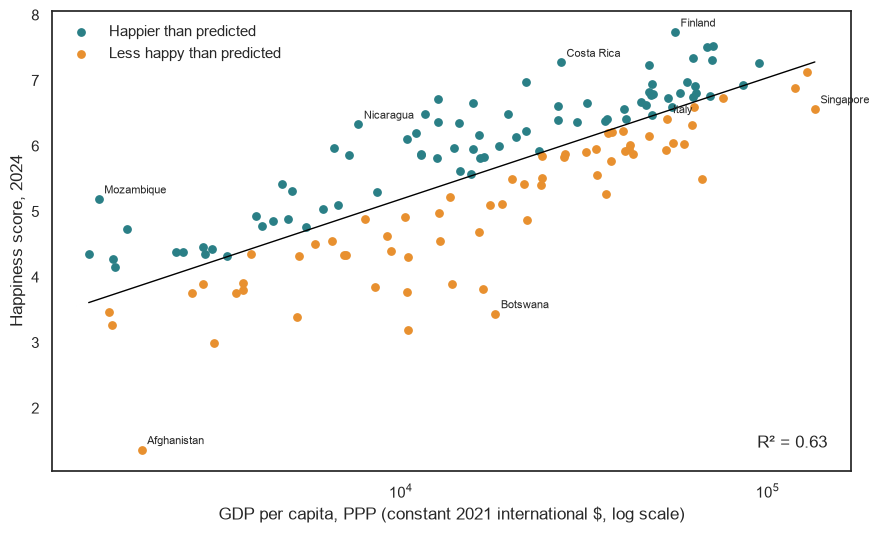

In [22]:

fig, ax = plt.subplots(figsize=(9, 5.5))
for g, colr in [("Happier than predicted", TEAL), ("Less happy than predicted", ORANGE)]:
    s = inc[inc["group"] == g]
    ax.scatter(s["gdp_ppp"], s["score"], c=colr, s=28, label=g)
xs = np.linspace(inc["ln_ppp"].min(), inc["ln_ppp"].max(), 50)
ax.plot(np.exp(xs), intercept + slope * xs, color="black", lw=1)
for c in ["Finland", "Costa Rica", "Nicaragua", "Mozambique", "Botswana", "Afghanistan", "Italy", "Singapore"]:
    r = inc[inc["country"] == c].iloc[0]
    ax.annotate(c, (r["gdp_ppp"], r["score"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set(xlabel="GDP per capita, PPP (constant 2021 international $, log scale)", ylabel="Happiness score, 2024")
ax.text(0.97, 0.05, f"R² = {r2:.2f}", transform=ax.transAxes, ha="right")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(OUT / "scatter_2024_draft.png", dpi=200)
plt.show()

In [23]:
# 8 biggest positive and 8 biggest negative gaps, plus ranks (out of the countries with income data)
inc["income_rank"] = inc["gdp_ppp"].rank(ascending=False).astype(int)
inc["happiness_rank"] = inc["score"].rank(ascending=False).astype(int)

bars = pd.concat([inc.nlargest(8, "gap"), inc.nsmallest(8, "gap")]).sort_values("gap", ascending=False)
bars["direction"] = np.where(bars["gap"] > 0, "Happier than income predicts", "Less happy than income predicts")
bars["gap_over_margin"] = (bars["gap"].abs() / bars["hw"]).round(1)

cols = ["country", "gap", "direction", "region", "score", "gdp_ppp", "income_rank", "happiness_rank", "gap_over_margin"]
bars[cols].round(2).to_csv(OUT / "flourish_gap_bars_ppp.csv", index=False)
print(len(inc), "countries")
bars[cols].round(2)

144 countries


,country,gap,direction,region,score,gdp_ppp,income_rank,happiness_rank,gap_over_margin
550,Mozambique,1.53,Happier than income predicts,Sub-Saharan Africa,5.19,1500.71,143,94,8.2
598,Nicaragua,1.36,Happier than income predicts,Central America & Caribbean,6.33,7661.09,106,46,9.4
94,Belize,1.34,Happier than income predicts,Central America & Caribbean,6.71,12621.41,90,25,4.8
177,Costa Rica,1.28,Happier than income predicts,Central America & Caribbean,7.27,27325.05,56,6,14.7
716,El Salvador,1.18,Happier than income predicts,Central America & Caribbean,6.49,11647.02,92,36,9.3
249,Finland,1.16,Happier than income predicts,Northern & Western Europe,7.74,55901.32,21,1,15.7
508,Mexico,1.16,Happier than income predicts,Central America & Caribbean,6.98,21970.35,64,10,12.9
315,Honduras,1.11,Happier than income predicts,Central America & Caribbean,5.96,6590.84,111,62,7.8
710,Sierra Leone,-1.24,Less happy than income predicts,Sub-Saharan Africa,3.00,3098.76,129,143,12.0
871,Zimbabwe,-1.27,Less happy than income predicts,Sub-Saharan Africa,3.40,5211.90,117,140,11.2


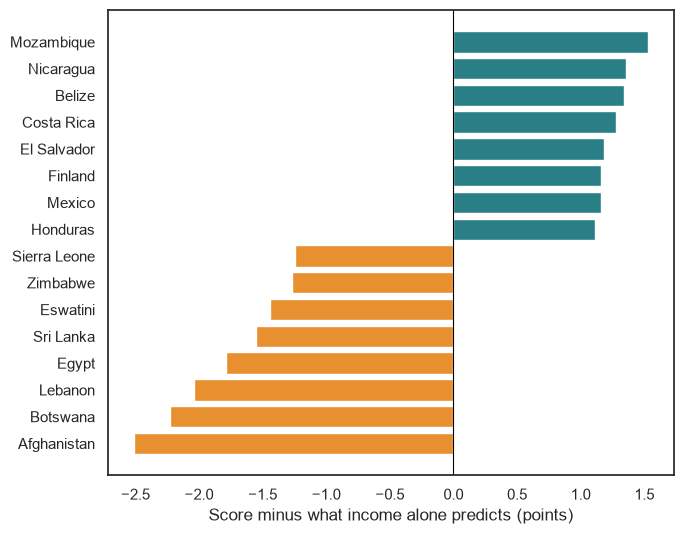

In [24]:
fig, ax = plt.subplots(figsize=(7, 5.5))
b = bars.iloc[::-1]
ax.barh(b["country"], b["gap"], color=[TEAL if g > 0 else ORANGE for g in b["gap"]])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Score minus what income alone predicts (points)")
plt.tight_layout()
plt.savefig(OUT / "gap_bars_draft.png", dpi=200)
plt.show()

In [25]:
def gaps_for(year):
    t = merged[merged["year"] == year].dropna(subset=["score", "gdp_ppp"]).copy()
    b_, a_ = np.polyfit(np.log(t["gdp_ppp"]), t["score"], 1)
    return t.set_index("iso3").eval("score - (@a_ + @b_ * log(gdp_ppp))")

both = pd.concat([gaps_for(2019), gaps_for(2024)], axis=1, join="inner")
print(round(both.corr().iloc[0, 1], 2), len(both))

0.84 141


## Profiles beyond income 
For 2024, social support, freedom, generosity, low corruption and health are each regressed on log GDP per capita (PPP) and only the
part left over is kept, so each value says how a country compares with others of the same income.
These are standardised and clustered with k-means (k = 3). Clusters are named from their average profile.

Note: the report also uses these ingredients to explain the score, so the link between profiles and the gap is partly built in.
The silhouette is low (about 0.2), the profiles overlap.

In [26]:
K, SEED = 3, 0
FEATURES = ["social", "freedom", "generosity", "corruption", "health"]
LABELS = {"social": "social support", "freedom": "freedom", "generosity": "generosity",
          "corruption": "low perceived\ncorruption", "health": "health"}
ORDER = ["Generous and trusting", "Close ties, weak trust and health", "Long-lived, less free"]

def residualise(y, x):
    return y - np.polyval(np.polyfit(x, y, 1), x)

d = merged[merged["year"] == 2024].set_index("country")
d = d[FEATURES + ["gdp_ppp", "score", "iso3"]].dropna()
log_inc = np.log(d["gdp_ppp"])

A = pd.DataFrame({c: residualise(d[c], log_inc) for c in FEATURES})
X = StandardScaler().fit_transform(A)
d["gap"] = residualise(d["score"], log_inc)
print(len(d))

141


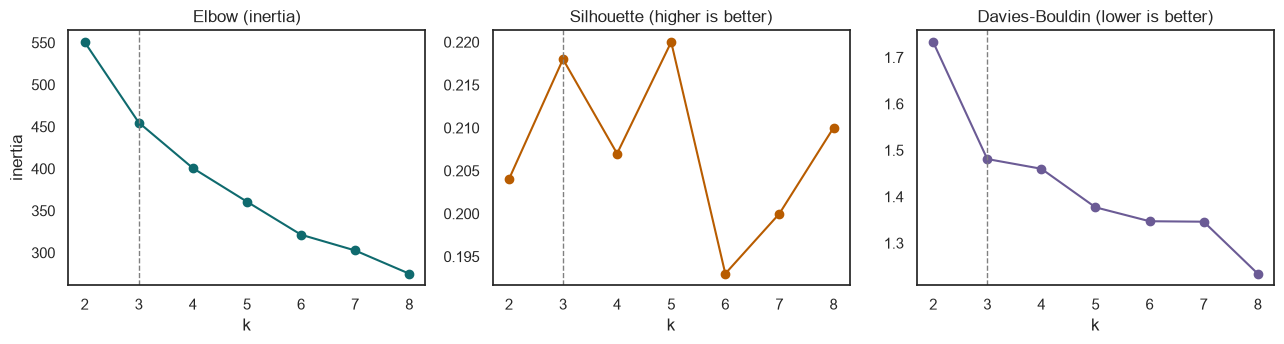

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,550.772,0.204,1.733,38.923
1,3,454.978,0.218,1.481,37.917
2,4,400.696,0.207,1.460,34.681
3,5,360.731,0.220,1.377,32.448
4,6,321.395,0.193,1.347,32.226
5,7,302.624,0.200,1.346,29.695
6,8,274.977,0.210,1.234,29.713


In [27]:
# elbow, silhouette and other validation scores, k = 2 to 8
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
validation = pd.DataFrame(rows).round(3)
validation.to_csv(OUT / "validation_k2_to_k8.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(validation.k, validation.inertia, "o-", color="#0f6a6e")
ax[0].set(title="Elbow (inertia)", xlabel="k", ylabel="inertia")
ax[1].plot(validation.k, validation.silhouette, "o-", color="#b85c00")
ax[1].set(title="Silhouette (higher is better)", xlabel="k")
ax[2].plot(validation.k, validation.davies_bouldin, "o-", color="#6B5B95")
ax[2].set(title="Davies-Bouldin (lower is better)", xlabel="k")
for a in ax:
    a.axvline(K, color="grey", ls="--", lw=1)
    a.set_xticks(validation.k)
plt.tight_layout()
plt.savefig(OUT / "elbow_silhouette.png", dpi=200)
plt.show()
validation

In [28]:
raw = KMeans(K, n_init=10, random_state=SEED).fit_predict(X)
d["silhouette"] = silhouette_samples(X, raw)

Z = (A - A.mean()) / A.std()
prof = Z.groupby(raw).mean()

# name the clusters from their profile, in case k-means numbers them differently
names = {prof["generosity"].idxmax(): ORDER[0], prof["social"].idxmin(): ORDER[2]}
for c in prof.index:
    names.setdefault(c, ORDER[1])
d["profile"] = pd.Series(raw, index=d.index).map(names)

print(d["profile"].value_counts().to_dict())
print(round(d["silhouette"].mean(), 3))
print(d.groupby("profile")["silhouette"].mean().round(3).to_dict())

{'Generous and trusting': 54, 'Close ties, weak trust and health': 53, 'Long-lived, less free': 34}
0.218
{'Close ties, weak trust and health': 0.271, 'Generous and trusting': 0.221, 'Long-lived, less free': 0.13}


In [29]:
H = prof.rename(index=names).loc[ORDER].round(2)
H.insert(0, "gap_vs_income", d.groupby("profile")["gap"].mean().loc[ORDER].round(2))
H.insert(0, "n_countries", d["profile"].value_counts().loc[ORDER])
H.index.name = "profile"
H.to_csv(OUT / "heatmap_wide.csv")

map_df = d.reset_index()[["country", "iso3", "profile", "gap", "score", "gdp_ppp", "silhouette"]].round(3)
map_df["is_italy"] = map_df["iso3"].eq("ITA")
map_df.to_csv(OUT / "flourish_clusters_map.csv", index=False)
H

,n_countries,gap_vs_income,social,freedom,generosity,corruption,health
profile,,,,,,,
Generous and trusting,54,0.33,0.27,0.53,0.79,0.67,0.43
"Close ties, weak trust and health",53,0.00,0.30,0.08,-0.46,-0.65,-0.84
"Long-lived, less free",34,-0.53,-0.90,-0.98,-0.54,-0.05,0.63


After inspection of the clusters created with other values, 3 was chosen also because it was the number that provided the most explainability in the profiles

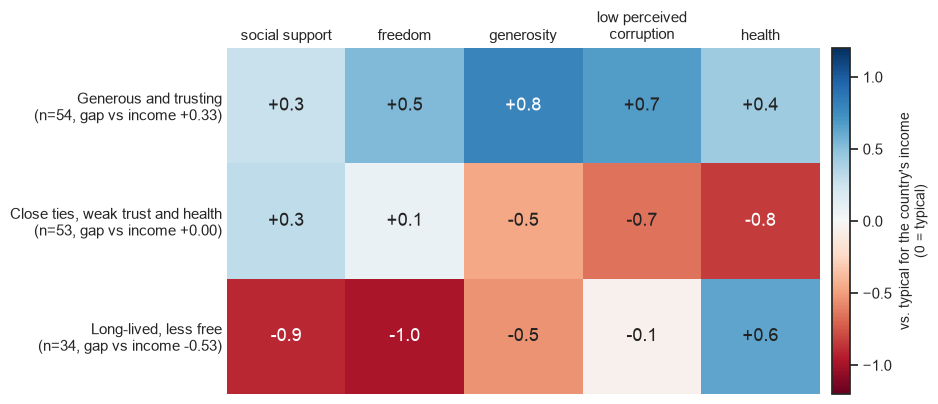

In [30]:
n, gp = d["profile"].value_counts(), d.groupby("profile")["gap"].mean()
ylabels = [f"{k}\n(n={n[k]}, gap vs income {gp[k]:+.2f})" for k in ORDER]
M = H[FEATURES]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
im = ax.imshow(M.values, cmap="RdBu", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(FEATURES)), [LABELS[c] for c in FEATURES], fontsize=11)
ax.set_yticks(range(K), ylabels, fontsize=11)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for (i, j), v in np.ndenumerate(M.values):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=13, color="white" if abs(v) > 0.7 else "#222")
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("vs. typical for the country's income\n(0 = typical)", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / "profiles_heatmap.png", dpi=200)
plt.show()

In [31]:
import plotly.express as px
import plotly.graph_objects as go

COLORS = {ORDER[0]: "#97C6BC", ORDER[1]: "#F0993F", ORDER[2]: "#3B8573"}
fig = px.choropleth(map_df, locations="iso3", color="profile", hover_name="country",
                    color_discrete_map=COLORS, category_orders={"profile": ORDER})
fig.add_trace(go.Choropleth(locations=["ITA"], z=[0], showscale=False, hoverinfo="skip",
                            colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]],
                            marker_line_color="black", marker_line_width=2.5))      # outline Italy
fig.update_geos(projection_type="natural earth", showframe=False, showcountries=True, countrycolor="white",
                showland=True, landcolor="#E6E6E6", showcoastlines=False)
fig.update_layout(title="What countries have beyond their income (2024)", legend_title_text="",
                  legend=dict(orientation="h", y=-0.05), margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "profiles_map.html")
fig.show()